# 06 — Card counting: what does each level of memory buy?

Notebook 03 showed a *perfect* deck tracker earns ~+9 points/game. But a
human doesn't remember everything. This notebook grades the memory:

| level | remembers |
|---|---|
| `hearts_count` | only *how many* hearts have been played |
| `hearts_exact` | *which* hearts have been played |
| `high_cards` | which high cards (off-suit A/K + hearts 9+, 12 cards) |
| `full` | every card (the notebook-03 tracker) |

and ablates *where* the memory is applied — the **bid channel** (across
rounds: the never-reshuffled deck means remembered cards partially predict
future deals) vs the **play channel** (within a round: prefer the cheapest
card whose survival probability against the unseen pool clears a
threshold), measured independently with paired seeds against matched
baselines (`heuristic` for play-only, `mc_bidder` for anything using the
bid channel).

Regenerate with:

```sh
uv run python -m hearts_analysis.experiments.counting \
    --games 1500 --mc-samples 200 --seed 8 --workers 8 --out data/counting
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hearts_analysis import viz

viz.use_style()
df = pd.read_parquet(Path("../data/counting/ablation.parquet"))

LEVELS = ["hearts_count", "hearts_exact", "high_cards", "full"]
CHANNEL_COLOR = {"play": viz.YELLOW, "bid": viz.BLUE, "bid+play": viz.VIOLET}

summary = (df.groupby(["level", "use"])["edge"]
             .agg(["mean", "std", "count"]).reindex(LEVELS, level=0))
summary["ci95"] = 1.96 * summary["std"] / np.sqrt(summary["count"])
summary.round(3)

mean    std  count   ci95
level        use                                 
hearts_count bid       0.000  0.000   1500  0.000
             bid+play  0.179  2.295   1500  0.116
             play      0.036  2.204   1500  0.112
hearts_exact bid       2.191  6.323   1500  0.320
             bid+play  1.957  6.315   1500  0.320
             play      0.040  2.269   1500  0.115
high_cards   bid       2.201  6.071   1500  0.307
             bid+play  2.038  6.054   1500  0.306
             play      0.041  2.269   1500  0.115
full         bid       8.888  6.923   1500  0.350
             bid+play  8.664  7.054   1500  0.357
             play      0.040  2.283   1500  0.116

## 1. The ladder, by channel

Each point: mean per-game edge over the matched baseline on 1,500 paired
games (identical decks and opponents; only seat 0's policy differs).

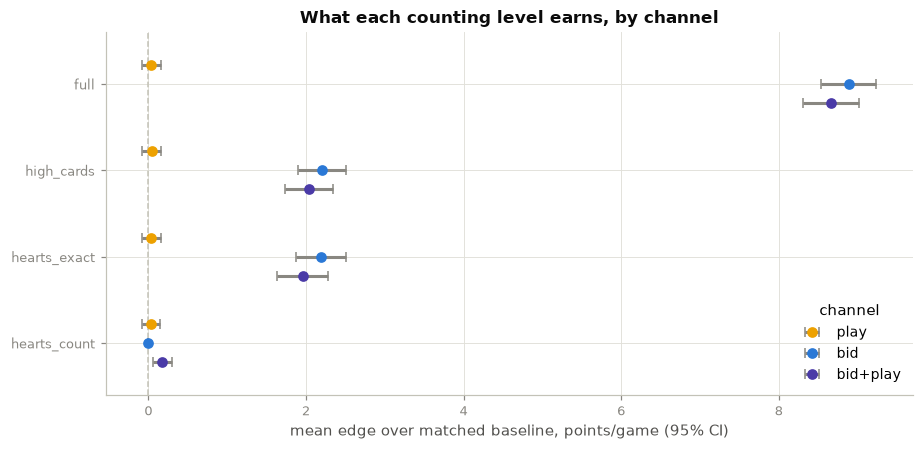

In [2]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ys = np.arange(len(LEVELS))
offsets = {"play": 0.22, "bid": 0.0, "bid+play": -0.22}
for use, color in CHANNEL_COLOR.items():
    s = summary.xs(use, level="use").reindex(LEVELS)
    ax.errorbar(s["mean"], ys + offsets[use], xerr=s["ci95"], fmt="o",
                color=color, ecolor=viz.MUTED, capsize=3, label=use)
ax.axvline(0, color=viz.BASELINE, linestyle="--", linewidth=1)
ax.set_yticks(ys, LEVELS)
ax.set_ylim(-0.6, len(LEVELS) - 0.4)
ax.set_xlabel("mean edge over matched baseline, points/game (95% CI)")
ax.set_title("What each counting level earns, by channel")
ax.legend(fontsize=9, title="channel", loc="lower right")
fig.tight_layout()

**Reading it:**

- **All of the value flows through bidding.** The bid channel earns
  +2.2 points/game from realistic memory (exact hearts, or just the 12
  high cards) and +8.9 from perfect memory — reproducing notebook 03's
  tracker edge as this ladder's top rung.
- **`hearts_count` earns exactly zero through bids by construction** — a
  count can't say *which seat* gets *which card*, so it adds nothing to
  the MC bidder's opponent model. Memory has to be about identities, not
  quantities.
- **`high_cards` ties `hearts_exact`** (+2.20 vs +2.19) while tracking 12
  specific cards instead of 13: remembering where the *winners* went is
  as good as remembering the whole trump suit — memory should chase
  trick-deciding cards, not suits.
- **The play channel is worth ≈0 at every level**, and `bid+play` is no
  better than `bid` alone. That null result is real and explained next.

## 2. Why within-round counting is worth so little

The play channel's confident-winner rule *does* fire — the question is
whether memory ever changes what it picks. Instrument every seat-0 play
decision over 200 games (no Monte Carlo, so this runs inline): how often
does each decision gate open, and how often does the confident set under
perfect memory differ from the one under count-only memory?

In [3]:
from hearts_analysis import runner
from hearts_analysis.cards import beats, suit_of, winning_play
from hearts_analysis.policies import CountingPolicy, HeuristicPolicy

stats = dict(plays=0, want_trick=0, lead_want=0, follow_contested=0,
             confident_full=0, confident_count=0, confident_sets_differ=0)

class Spy(CountingPolicy):
    def __init__(self):
        super().__init__("full", use_for=("play",))
        self.coarse = CountingPolicy("hearts_count", use_for=("play",))
    def reset(self, seat, n, rng):
        super().reset(seat, n, rng)
        self.coarse.reset(seat, n, rng)
    def play(self, obs):
        stats["plays"] += 1
        legal = obs.legal_plays
        want = obs.my_tricks < (obs.my_bid or 0)
        if want and len(legal) > 1:
            stats["want_trick"] += 1
            pool_f = self._possible_unseen(obs)
            pool_c = self.coarse._possible_unseen(obs)
            h = obs.cards_this_round - len(obs.round_tricks)
            if not obs.current_trick:
                stats["lead_want"] += 1
                m = (obs.num_players - 1) * h
                cf = [c for c in legal if self._p_survives(c, suit_of(c), pool_f, m) >= 0.9]
                cc = [c for c in legal if self._p_survives(c, suit_of(c), pool_c, m) >= 0.9]
            else:
                led = obs.led_suit
                _, best = winning_play(obs.current_trick, led)
                winners = [c for c in legal if beats(c, best, led)]
                cf = cc = []
                if winners and len(obs.current_trick) < obs.num_players - 1:
                    stats["follow_contested"] += 1
                    m = (obs.num_players - 1 - len(obs.current_trick)) * h
                    cf = [c for c in winners if self._p_survives(c, led, pool_f, m) >= 0.9]
                    cc = [c for c in winners if self._p_survives(c, led, pool_c, m) >= 0.9]
            stats["confident_full"] += bool(cf)
            stats["confident_count"] += bool(cc)
            stats["confident_sets_differ"] += cf != cc
        return super().play(obs)

spy = Spy()
for seed in range(200):
    runner.play_game([spy] + [HeuristicPolicy() for _ in range(3)], game_seed=seed)
pd.Series(stats, name="count over 200 games (4p)").to_frame()

,count over 200 games (4p)
plays,9800
want_trick,3399
lead_want,1041
follow_contested,596
confident_full,152
confident_count,140
confident_sets_differ,16


**Reading it:** the gates open constantly (~5 wanted leads per game), and
the policy *is* confident a fair fraction of the time — but the confident
set under perfect memory and under count-only memory almost never differs,
and when it does, the extra cards memory promotes are usually the same top
heart the memoryless baseline would have led anyway.

The structural reason: at a 4-player table only 28 of 52 cards are dealt
in even the biggest round, and a within-round counter cannot distinguish
"not yet played" from "never dealt." The unseen pool is dominated by
undealt cards no opponent holds, so memory of the few cards actually
played barely moves any survival probability. Within-round counting is
low-value *by the game's design* — short rounds, partial deals.

The deck's cross-round determinism is the exact opposite: there, public
history pins down *future deals* completely (notebook 03), which is why
the same memories are worth +2 to +9 points when routed into bidding.

## 3. Takeaways

1. **Count cards for your *bids*, not your plays.** Every point of
   counting value arrives through better bidding (sharper opponent-hand
   knowledge in the never-reshuffled deck); within-round play adjustments
   are worth ≈0 at any memory level.
2. **Identities beat quantities**: "how many hearts are gone" earns
   exactly nothing; "which hearts" earns +2.2/game.
3. **Track winners, not suits**: the 12 trick-deciding high cards match
   the full 13-card trump suit, point for point.
4. **The ceiling is +8.9/game with perfect memory** — consistent with
   notebook 03's deck tracker, now decomposed: essentially all of it is
   the bid channel.
5. Together with notebook 05: bidding strategy (+16 over random), then
   counting-informed bidding (+2 to +9 over a strong bidder), then play
   style (±1–2) — that's the value hierarchy of skill in this game.